In [1]:
import numpy as np
import pandas as pd

In [2]:
from scipy.io import loadmat

In [3]:
data = loadmat('ASOW6_ensemble_prediction.mat')

In [4]:
short = loadmat('asow_test_results_hour_train10_multi1_th90.mat')
long = loadmat('asow_airu_train60_multi1_th50.mat')

In [5]:
long['allY_Fore'].shape

(24, 4, 184)

In [6]:
asow_short = short['allY_Fore'][:,2,:183]
asow_long = long['allY_Fore'][:,2,:183]

In [7]:
asow_short.shape

(24, 183)

In [9]:
sigma_short = short['allVariance'][0+24*2:24*3,0+24*2:24*3,:183]
sigma_long = long['allVariance'][0+24*2:24*3,0+24*2:24*3,:183]

In [10]:
ens = loadmat('/Users/jijiaxiang/Matlab/Ensemble/ensemble_es_constrain.mat')

In [11]:
ens.keys()

dict_keys(['__header__', '__version__', '__globals__', 'mu', 'Sigma', 'Error', 'alpha', 'ell', 'rho', 'MAE_daily', 'ES_daily', 'y_true'])

In [12]:
import numpy as np

def symmetrize(A):
    return 0.5 * (A + A.T)


def nearest_psd(A, eps=1e-8):
    A = symmetrize(A)
    vals, vecs = np.linalg.eigh(A)
    vals = np.maximum(vals, eps)
    return vecs @ np.diag(vals) @ vecs.T


def matrix_sqrt_psd(A, eps=1e-8):
    A = nearest_psd(A, eps=eps)
    vals, vecs = np.linalg.eigh(A)
    vals = np.maximum(vals, eps)
    return vecs @ np.diag(np.sqrt(vals)) @ vecs.T


def temporal_kernel_R(H, ell):
    idx = np.arange(H)
    dist2 = (idx[:, None] - idx[None, :]) ** 2
    return np.exp(-dist2 / (2 * ell**2))


def get_weight_from_alpha(alpha, H=24, horizon_start=1):
    """
    Construct short-model weights from alpha.

    If horizon_start=1:
        h = 1, 2, ..., 24
    If horizon_start=0:
        h = 0, 1, ..., 23

    Usually for forecast horizon, h=1,...,24 is more natural.
    """
    h = np.arange(horizon_start, horizon_start + H)
    w_short = np.exp(-alpha * h)
    return w_short
def ensemble_new_location_from_alpha(
    mu_short,
    mu_long,
    Sigma_short,
    Sigma_long,
    results,
    start_idx=45,
    horizon_start=1,
    eps=1e-8
):
    """
    Compute ensemble predictive mean and covariance for a new location
    using saved alpha, ell, rho.

    Parameters
    ----------
    mu_short : array
        Short-term mean, shape (24, D) or (D, 24)

    mu_long : array
        Long-term mean, shape (24, D) or (D, 24)

    Sigma_short : array
        Short-term covariance, shape (24, 24, D) or (D, 24, 24)

    Sigma_long : array
        Long-term covariance, shape (24, 24, D) or (D, 24, 24)

    results : dict
        Loaded ensemble results.
        Need keys: alpha, ell, rho.

    start_idx : int
        The first prediction day corresponding to the rolling ensemble.
        Usually 45 because ensemble parameters are estimated using previous 45 days.

    horizon_start : int
        Use 1 if h = 1,...,24.
        Use 0 if your original code used h = 0,...,23.

    Returns
    -------
    mu_ens : array
        Ensemble mean, shape (24, n_eff)

    Sigma_ens : array
        Ensemble covariance, shape (24, 24, n_eff)
    """

    mu_short = np.asarray(mu_short)
    mu_long = np.asarray(mu_long)
    Sigma_short = np.asarray(Sigma_short)
    Sigma_long = np.asarray(Sigma_long)

    # --------------------------------------------------------
    # Standardize mean shape to (H, D)
    # --------------------------------------------------------
    if mu_short.shape[0] != 24 and mu_short.shape[1] == 24:
        mu_short = mu_short.T

    if mu_long.shape[0] != 24 and mu_long.shape[1] == 24:
        mu_long = mu_long.T

    H, D = mu_short.shape

    assert H == 24, f"Expected H=24, got H={H}"
    assert mu_long.shape == (H, D), "mu_long shape must match mu_short"

    # --------------------------------------------------------
    # Standardize covariance shape to (H, H, D)
    # --------------------------------------------------------
    if Sigma_short.shape[0] != H and Sigma_short.shape[1] == H and Sigma_short.shape[2] == H:
        Sigma_short = np.transpose(Sigma_short, (1, 2, 0))

    if Sigma_long.shape[0] != H and Sigma_long.shape[1] == H and Sigma_long.shape[2] == H:
        Sigma_long = np.transpose(Sigma_long, (1, 2, 0))

    assert Sigma_short.shape == (H, H, D), f"Wrong Sigma_short shape: {Sigma_short.shape}"
    assert Sigma_long.shape == (H, H, D), f"Wrong Sigma_long shape: {Sigma_long.shape}"

    # --------------------------------------------------------
    # Load saved rolling parameters
    # --------------------------------------------------------
    alpha_seq = np.asarray(results["alpha"]).reshape(-1)
    ell_seq = np.asarray(results["ell"]).reshape(-1)
    rho_seq = np.asarray(results["rho"]).reshape(-1)

    n_eff = len(alpha_seq)

    assert len(ell_seq) == n_eff, "ell length does not match alpha length"
    assert len(rho_seq) == n_eff, "rho length does not match alpha length"

    assert start_idx + n_eff <= D, (
        f"start_idx + n_eff = {start_idx + n_eff}, but D = {D}. "
        "Check whether ASOW-6 predictions have enough rolling days."
    )

    mu_ens = np.zeros((H, n_eff))
    Sigma_ens = np.zeros((H, H, n_eff))

    # ========================================================
    # Rolling ensemble prediction
    # ========================================================
    for r in range(n_eff):

        d = start_idx + r

        alpha = float(alpha_seq[r])
        ell = float(ell_seq[r])
        rho = float(rho_seq[r])

        # Short-model weight
        w = get_weight_from_alpha(
            alpha=alpha,
            H=H,
            horizon_start=horizon_start
        )

        W = np.diag(w)
        I_W = np.diag(1.0 - w)

        # Means
        mu_s = mu_short[:, d]
        mu_l = mu_long[:, d]

        mu_z = w * mu_s + (1.0 - w) * mu_l

        # Covariances
        Sig_s = nearest_psd(Sigma_short[:, :, d], eps=eps)
        Sig_l = nearest_psd(Sigma_long[:, :, d], eps=eps)

        R_ell = temporal_kernel_R(H, ell)

        Sig_s_sqrt = matrix_sqrt_psd(Sig_s, eps=eps)
        Sig_l_sqrt = matrix_sqrt_psd(Sig_l, eps=eps)

        # Cross-model covariance
        Sig_sl = rho * Sig_s_sqrt @ R_ell @ Sig_l_sqrt
        Sig_ls = Sig_sl.T

        # Ensemble covariance
        Sig_z = (
            W @ Sig_s @ W
            + I_W @ Sig_l @ I_W
            + W @ Sig_sl @ I_W
            + I_W @ Sig_ls @ W
        )

        Sig_z = nearest_psd(Sig_z, eps=eps)

        mu_ens[:, r] = mu_z
        Sigma_ens[:, :, r] = Sig_z

    return mu_ens, Sigma_ens

In [13]:
mu_ens_asow, Sigma_ens_asow = ensemble_new_location_from_alpha(
    mu_short=asow_short,
    mu_long=asow_long,
    Sigma_short=sigma_short,
    Sigma_long=sigma_long,
    results=ens,
    start_idx=45
)

In [14]:
mu_ens_asow.shape

(24, 138)

In [15]:
var_ASOW = np.diagonal(Sigma_ens_asow, axis1 = 0, axis2=1)

In [23]:
std_ens_asow = np.sqrt(var_ASOW).T

In [24]:
mu = mu_ens_asow.reshape(-1, order = "F")
sigma = std_ens_asow.reshape(-1,order = "F")

In [53]:
mu

array([ 8.43476471,  6.17486546,  5.16222004, ..., 11.41470485,
       11.11885084, 10.46683117])

In [37]:
pred = data['ASOW6_ensemble_pred']

In [38]:
pred[-3312:]

array([[ 5.18799307],
       [ 6.40913068],
       [ 6.09563298],
       ...,
       [10.28082055],
       [10.07833534],
       [ 9.57079117]])

In [39]:
short_pred = short['allY_Fore'][:,:,:183]
long_pred = long['allY_Fore'][:,:,:183]

In [40]:
data = loadmat('ensemble_asow_new.mat')

In [41]:
pred = data['Y_pred'][:,2,:]

In [42]:
pred_asow = pred.reshape(-1, order="F")

In [43]:
short_asow = short_pred[:,2,:].reshape(-1,order = "F")
long_asow = long_pred[:,2,:].reshape(-1, order = "F")

In [44]:
pred_asow

array([ 0.        ,  0.        ,  0.        , ..., 11.41470485,
       11.11885084, 10.46683117])

In [45]:
asow = pd.read_csv('ASOW6.csv')

In [46]:
asow_true = asow['asow6_140m_ws']

In [47]:
import pandas as pd

df = pd.read_csv("ASOW6.csv")

df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)

df["hour"] = df["timestamp"].dt.floor("h")

df_hour_gt = (
    df.groupby("hour", as_index=False)["asow6_140m_ws"]
      .mean()
      .rename(columns={
          "hour": "timestamp",
          "asow6_140m_ws": "ground_truth"
      })
)

start_time = pd.Timestamp("2020-01-30 00:00:00", tz="UTC")
end_time = df_hour_gt["timestamp"].max()

full_hours = pd.date_range(
    start=start_time,
    end=end_time,
    freq="h",
    tz="UTC"
)

df_hour_gt = (
    df_hour_gt
    .set_index("timestamp")
    .reindex(full_hours)
    .rename_axis("timestamp")
    .reset_index()
)

print(df_hour_gt.head())
print(df_hour_gt.tail())
print(df_hour_gt.shape)

                  timestamp  ground_truth
0 2020-01-30 00:00:00+00:00           NaN
1 2020-01-30 01:00:00+00:00           NaN
2 2020-01-30 02:00:00+00:00           NaN
3 2020-01-30 03:00:00+00:00           NaN
4 2020-01-30 04:00:00+00:00           NaN
                      timestamp  ground_truth
11289 2021-05-14 09:00:00+00:00      8.718898
11290 2021-05-14 10:00:00+00:00      7.643652
11291 2021-05-14 11:00:00+00:00      4.922283
11292 2021-05-14 12:00:00+00:00      2.838563
11293 2021-05-14 13:00:00+00:00      2.751440
(11294, 2)


In [48]:
data_Test = df_hour_gt[1080:4392]

In [49]:
data_Test['pred'] = mu

/var/folders/z4/sfjcxx3s1px_qp22m2z82c9m0000gn/T/ipykernel_55863/3177565208.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_Test['pred'] = mu


In [50]:
data_Test['std'] = sigma

/var/folders/z4/sfjcxx3s1px_qp22m2z82c9m0000gn/T/ipykernel_55863/1952519343.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_Test['std'] = sigma


In [ ]:
#### LTM 2.332/STM 2.370 // our 2.314

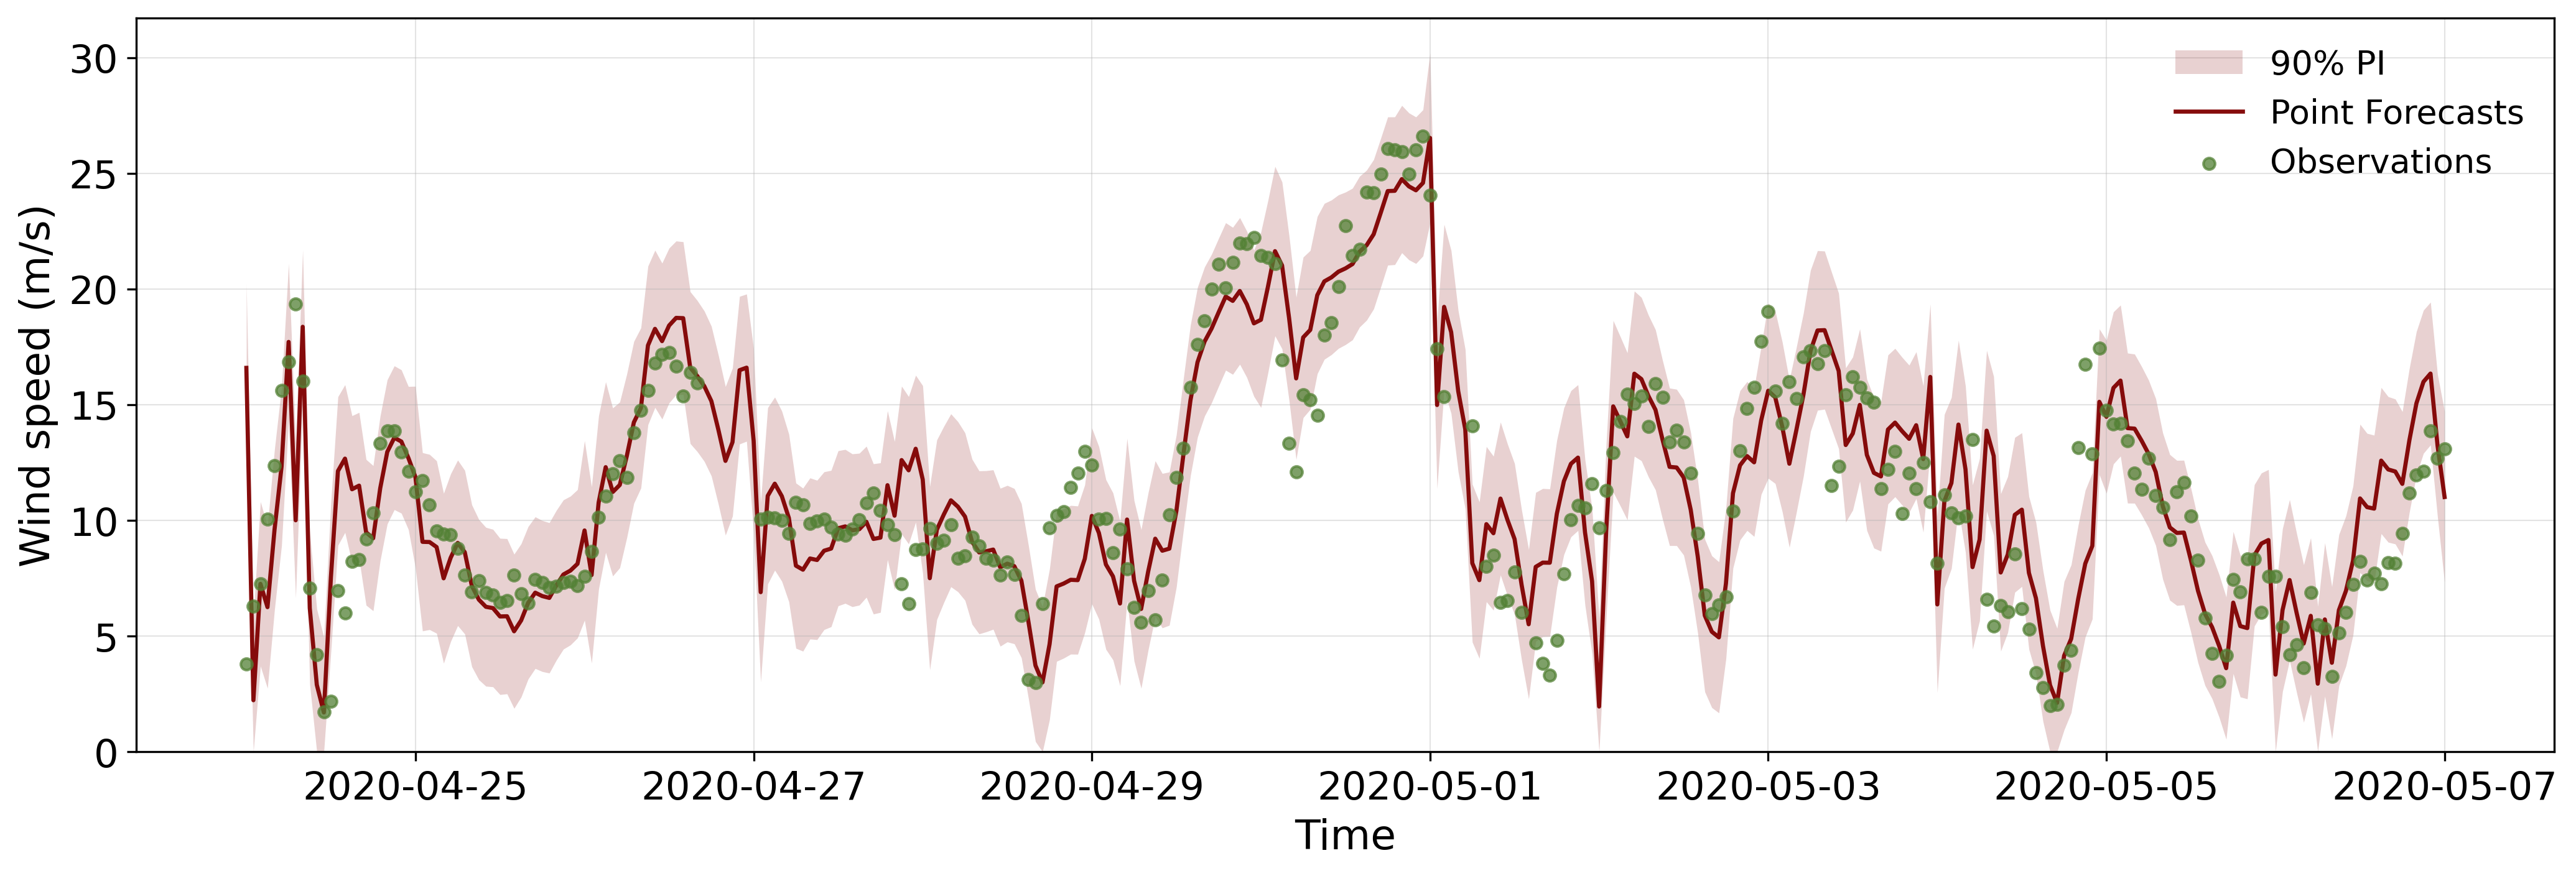

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df_plot = data_Test.copy()
df_plot["timestamp"] = pd.to_datetime(df_plot["timestamp"])

# Optional: remove timezone for cleaner plotting
if df_plot["timestamp"].dt.tz is not None:
    df_plot["timestamp"] = df_plot["timestamp"].dt.tz_convert(None)

df_plot = df_plot[
    (df_plot["timestamp"] >= "2020-04-24") &
    (df_plot["timestamp"] <= "2020-05-07")
].copy()

# Make sure numeric
df_plot["ground_truth"] = pd.to_numeric(df_plot["ground_truth"], errors="coerce")
df_plot["pred"] = pd.to_numeric(df_plot["pred"], errors="coerce")
df_plot["std"] = pd.to_numeric(df_plot["std"], errors="coerce")

# Sort by time, important for fill_between
df_plot = df_plot.sort_values("timestamp")

# =========================
# 90% confidence / prediction interval
# =========================
z90 = 1.645

df_plot["lower_90"] = df_plot["pred"] - z90 * df_plot["std"]
df_plot["upper_90"] = df_plot["pred"] + z90 * df_plot["std"]

# Optional: wind speed cannot be negative
df_plot["lower_90"] = df_plot["lower_90"].clip(lower=0)

# =========================
# Plot full time series
# =========================
fig, ax = plt.subplots(figsize=(14, 4.8), dpi=300)

# 90% interval
ax.fill_between(
    df_plot["timestamp"],
    df_plot["lower_90"],
    df_plot["upper_90"],
    color="maroon",
    alpha=0.18,
    linewidth=0,
    label="90% PI"
)

# Point forecast line
ax.plot(
    df_plot["timestamp"],
    df_plot["pred"],
    color="maroon",
    linewidth=1.6,
    alpha=0.95,
    label="Point Forecasts"
)

# Ground truth as points
ax.scatter(
    df_plot["timestamp"],
    df_plot["ground_truth"],
    s=20,
    color="#538135",
    alpha=0.75,
    label="Observations",
    zorder=3
)

# Labels
ax.set_xlabel("Time", fontsize=16)
ax.set_ylabel("Wind speed (m/s)", fontsize=16)
ax.set_ylim(bottom = 0)
# Style
ax.grid(True, linewidth=0.5, alpha=0.35)
ax.legend(frameon=False, fontsize=13, loc="upper right")

ax.tick_params(axis="both", labelsize=15)
plt.setp(ax.get_xticklabels(), rotation=0, ha="center")

fig.tight_layout()

# Save high-quality figure
#fig.savefig("ASOW6_timeseries_forecast_truth_90PI.png", dpi=600, bbox_inches="tight")
# fig.savefig("ASOW6_timeseries_forecast_truth_90PI.pdf", bbox_inches="tight")
plt.show()